In [ ]:
!pip -q install datasets[audio] librosa soundfile scikit-learn joblib

In [ ]:
import numpy as np
import pandas as pd
import librosa
import joblib

from datasets import load_dataset, concatenate_datasets
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from tqdm.auto import tqdm

np.random.seed(42)

In [ ]:
dfadd = load_dataset(
    "SpeechAntiSpoofingBenchmarks/DFADD",
    split="test"
)

bonafide = dfadd.filter(lambda x: x["label"] == 0)
spoof = dfadd.filter(lambda x: x["label"] == 1)

spoof = spoof.shuffle(seed=42).select(
    range(len(bonafide))
)

balanced_dataset = concatenate_datasets([
    bonafide,
    spoof
]).shuffle(seed=42)

print("Total samples:", len(balanced_dataset))
print("Bonafide:", sum(np.array(balanced_dataset["label"]) == 0))
print("Spoof:", sum(np.array(balanced_dataset["label"]) == 1))

Filter:   0%|          | 0/3755 [00:00<?, ? examples/s]

Total samples: 1510
Bonafide: 755
Spoof: 755


In [ ]:
def extract_features(audio_data, sr=16000):
    signal = np.asarray(audio_data, dtype=np.float32)

    if len(signal) == 0:
        return None

    signal = signal / (np.max(np.abs(signal)) + 1e-8)

    mfcc = librosa.feature.mfcc(
        y=signal,
        sr=sr,
        n_mfcc=40
    )

    return np.concatenate([
        np.mean(mfcc, axis=1),
        np.std(mfcc, axis=1),
        [np.mean(librosa.feature.zero_crossing_rate(signal))],
        [np.mean(librosa.feature.spectral_centroid(y=signal, sr=sr))],
        [np.mean(librosa.feature.spectral_bandwidth(y=signal, sr=sr))],
        [np.mean(librosa.feature.rms(y=signal))]
    ])

In [ ]:
X = []
y = []

for i in tqdm(range(len(balanced_dataset))):
    audio = balanced_dataset[i]["audio"]

    features = extract_features(
        audio["array"],
        audio["sampling_rate"]
    )

    if features is not None:
        X.append(features)
        y.append(balanced_dataset[i]["label"])

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int32)

print("X shape:", X.shape)
print("y shape:", y.shape)

  0%|          | 0/1510 [00:00<?, ?it/s]

X shape: (1510, 84)
y shape: (1510,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1208
Testing samples: 302


In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
rf_predictions = rf_model.predict(
    X_test
)

rf_probabilities = rf_model.predict_proba(
    X_test
)[:, 1]

rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_predictions),
    "Precision": precision_score(y_test, rf_predictions),
    "Recall": recall_score(y_test, rf_predictions),
    "F1 Score": f1_score(y_test, rf_predictions),
    "ROC-AUC": roc_auc_score(y_test, rf_probabilities)
}

rf_results_df = pd.DataFrame([rf_results])

display(
    rf_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.9503,0.9595,0.9404,0.9498,0.9916


In [ ]:
print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=["Bonafide", "Spoof"]
    )
)

              precision    recall  f1-score   support

    Bonafide       0.94      0.96      0.95       151
       Spoof       0.96      0.94      0.95       151

    accuracy                           0.95       302
   macro avg       0.95      0.95      0.95       302
weighted avg       0.95      0.95      0.95       302



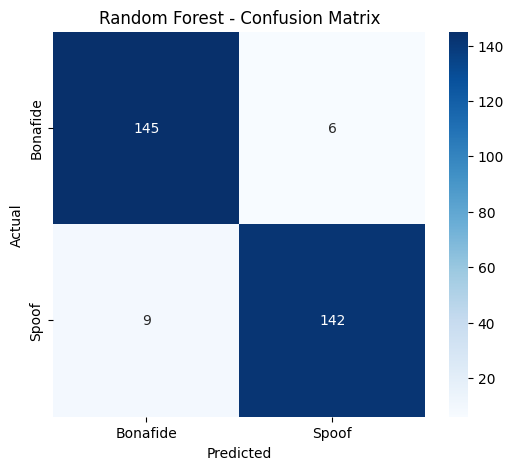

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    rf_predictions
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Bonafide", "Spoof"],
    yticklabels=["Bonafide", "Spoof"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
joblib.dump(
    rf_model,
    "/content/VoiceGuard_RandomForest_model.pkl"
)

rf_results_df.to_csv(
    "/content/VoiceGuard_RandomForest_results.csv",
    index=False
)

print("Random Forest model and results saved!")

Random Forest model and results saved!
